In [1]:
from skyfield.api import load, wgs84
import numpy as np
from numpy import array2string
from datetime import datetime, timedelta
import os
from scipy import io as sio
import pytz
import math
import scipy.io
import satfunc


In [2]:
# TODO: define constants and set other parameters
c = 299792458.0 # speed of light in m/s
fc = 11.575e9 # carrier frequency in Hz
f = 0.2e6 # narrowband tone freq in Hz
lo = 9.75e9 # local oscillator frequency in Hz
fs = 1e2 # sampling frequency in Hz
lam = c/fc # wavelength in m
d = lam/2 # antenna spacing in m
num_ant = 4 # number of antennas
re = 6378e3 # earth radius in m
min_elevation = 60 # minimum elevation of visible sats


In [25]:
# Load tle from path

# change the path
# path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
path = '/home/ishani/LeoPNT/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
# path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\11_5\\STARLINK-5718.tle'

satellites = load.tle_file(path)
print(satellites)

# % assume we have 4 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB2 LNB4 |       W + E
# | LNB1 LNB3 |         S
#  ------------
# initialize location of 4 LNBs with lat, lon = +40.11389690596162, -88.22484814695467 (UIUC)

lat_1, lon_1 = +40.11389690596162, -88.22484814695467
lnb_1 = wgs84.latlon(lat_1, lon_1)
lnb_2 = wgs84.latlon(lat_1+np.rad2deg(d/re), lon_1)
lnb_3 = wgs84.latlon(lat_1, lon_1+np.rad2deg(d/re)/np.cos(np.deg2rad(lat_1)))
lnb_4 = wgs84.latlon(lat_1+np.rad2deg(d/re), lon_1+np.rad2deg(d/re)/np.cos(np.deg2rad(lat_1)))
lnbs = [lnb_1, lnb_2, lnb_3, lnb_4]

# set start time and stop time, add 5 hours to account for time zone difference
ts = load.timescale()
start_time = datetime(2023, 10, 30, 23, 55, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 10, 31, 0, 5, 0, tzinfo=pytz.UTC)+timedelta(hours=5)
# start_time = datetime(2023, 11, 4, 23, 55, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
# stop_time = datetime(2023, 11, 5, 0, 5, 0, tzinfo=pytz.UTC)+timedelta(hours=5)

[<EarthSatellite STARLINK-6150 catalog #57119 epoch 2023-10-31 06:43:42 UTC>]


The following section tries to estimate the AoA (both azimuth & elevation) using MUSIC.

Assume that the satellite is transmitting at frequency $f_c+f=11.575 GHz+0.2 MHz$, i.e.,
$$y(t) = \exp(j2\pi(f+f_c)t),$$
where $f_c$ is the carrier frequency and $f$ is the narrowband tone's frequency.

Assume when it arrives at LNB-1 at UIUC, it becomes 
$$y_1(t) = A\exp(j2\pi(f+f_c)t)+n_1,$$
where $A$ is path loss, $n_1$ is the noise at LNB-1.

Similarly, for LNB-i (i=2,3,4), there will be time delays since the distance between LNB-i will be different from LNB-1, given by
$$y_i(t) = A\exp(j2\pi(f+f_c)\times (t-(r_i-r_1)/c))+n_i, \\
 = A\exp(-j2\pi(f+f_c)*(r_i-r_1)/c)\times \exp(j2\pi(f+f_c)t)+n_i, \\
 = A'\exp(j2\pi(f+f_c)t)+n_i,$$
where $r_i$ is the distance between the sat and the i-th LNB. If $r_i>r_1$ then it arrives later. Also assume that $A$ is same for different LNBs since they are very close to each other.

$y_i(t)$ is in anaglog domain, then LNB \& USRP down-converts it at sample it. In the most ideal case where we have synchronized LNBs and USRPs, the digital signal we get is removing $f_c$ and substituting continuous time $t$ with discrete time samples $n*T_s = n/F_s$, i.e.,
$$y_i[n] = A'\exp(j2\pi f n/f_s)+n_i,$$
from where we start our simulation

In [26]:
# get start time as ts.utc
t = ts.utc(start_time)
n = np.arange(0, fs*60*10, 1)
i = 0

received_sig = np.empty((num_ant, len(n)), dtype=complex)
range_ = np.empty((num_ant, len(n)))

# array to record elevation and azimuth of satellite from 4 lnbs
el_gt = np.empty(len(n))
az_gt = np.empty(len(n))

while True:
    dist1 = (satellites[0]-lnb_1).at(t)
    el1, az1, distance1 = dist1.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el1.degrees, az1.degrees)
    _, _, the_range1, _, _, range_rate1 = dist1.frame_latlon_and_rates(lnb_1)
    doppler_shift1 = (fc)*range_rate1.km_per_s*1000/c

    dist2 = (satellites[0]-lnb_2).at(t)
    el2, az2, distance2 = dist2.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el2.degrees, az2.degrees)
    _, _, the_range2, _, _, range_rate2 = dist2.frame_latlon_and_rates(lnb_2)
    doppler_shift2 = (fc)*range_rate2.km_per_s*1000/c

    dist3 = (satellites[0]-lnb_3).at(t)
    el3, az3, distance3 = dist3.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el3.degrees, az3.degrees)
    _, _, the_range3, _, _, range_rate3 = dist3.frame_latlon_and_rates(lnb_3)
    doppler_shift3 = (fc)*range_rate3.km_per_s*1000/c

    dist4 = (satellites[0]-lnb_4).at(t)
    el4, az4, distance4 = dist4.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el4.degrees, az4.degrees)
    _, _, the_range4, _, _, range_rate4 = dist4.frame_latlon_and_rates(lnb_4)
    doppler_shift4 = (fc)*range_rate4.km_per_s*1000/c

    received_sig[0, i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range1.km/c*1000.0) # np.exp(-1j*2*np.pi*(f+doppler_shift1)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range1.km/c*1000.0)
    received_sig[1, i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range2.km/c*1000.0) # np.exp(-1j*2*np.pi*(f+doppler_shift2)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range2.km/c*1000.0)
    received_sig[2, i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range3.km/c*1000.0) # np.exp(-1j*2*np.pi*(f+doppler_shift3)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range3.km/c*1000.0)
    received_sig[3, i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range4.km/c*1000.0) # np.exp(-1j*2*np.pi*(f+doppler_shift4)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range4.km/c*1000.0)
    
    range_[0,i], range_[1,i], range_[2,i], range_[3,i] = the_range1.km, the_range2.km, the_range3.km, the_range4.km

    el_gt[i] = float(el1.degrees)
    az_gt[i] = float(az1.degrees)

    # increment t which is ts.utc by 1 second
    t = ts.utc(t.utc_datetime()+timedelta(milliseconds=1000/fs)) # TODO: fix this
    i += 1
    print(i)

    if t.utc_datetime() >= stop_time:
        break

2023-10-31T04:55:00Z 4.623830910045643 287.4495182092127
2023-10-31T04:55:00Z 4.6238309527989 287.4495178886922
2023-10-31T04:55:00Z 4.623830773933218 287.44951820608816
2023-10-31T04:55:00Z 4.62383081668647 287.4495178855676
1
2023-10-31T04:55:00Z 4.624560339567291 287.44954804065037
2023-10-31T04:55:00Z 4.62456038232209 287.4495477201191
2023-10-31T04:55:00Z 4.624560203450191 287.4495480375223
2023-10-31T04:55:00Z 4.624560246204981 287.44954771699093
2
2023-10-31T04:55:00Z 4.62528979418252 287.4495778720499
2023-10-31T04:55:00Z 4.62528983693884 287.4495775515078
2023-10-31T04:55:00Z 4.625289658060734 287.4495778689182
2023-10-31T04:55:00Z 4.625289700817053 287.4495775483761
3
2023-10-31T04:55:00Z 4.626019273888144 287.4496077034112
2023-10-31T04:55:00Z 4.626019316646004 287.44960738285835
2023-10-31T04:55:00Z 4.626019137761715 287.44960770027586
2023-10-31T04:55:00Z 4.626019180519576 287.4496073797231
4
2023-10-31T04:55:00Z 4.626748778688897 287.4496375347343
2023-10-31T04:55:00Z 4.6

In [27]:
received_sig_noisy = np.empty((num_ant, len(n)), dtype=complex)
for i in range(num_ant):
    received_sig_noisy[i,:] = satfunc.add_awgn(received_sig[i,:], 20)

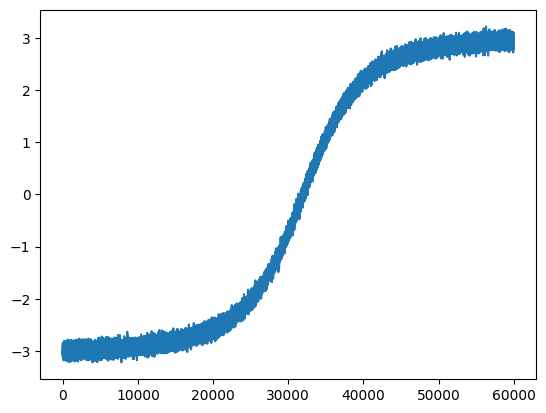

In [28]:
# plotting the phase difference between received signals
import matplotlib.pyplot as plt
del_phi = np.unwrap(np.angle(received_sig_noisy[0,:]/received_sig[2,:]))
plt.plot(del_phi)

/tmp/ipykernel_285852/1133724726.py:6: RuntimeWarning: invalid value encountered in arccos
  el = np.arccos(del_phi_1*lam/(2*np.pi*d*np.sin(az)))


[]

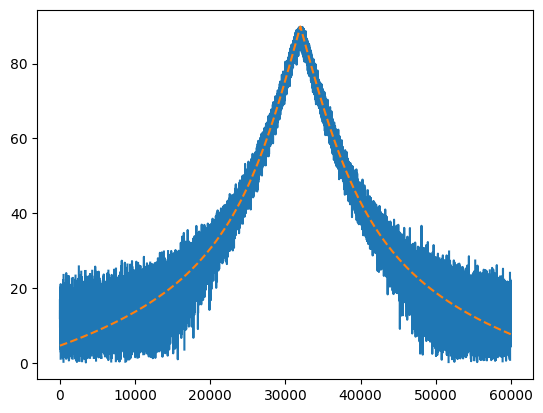

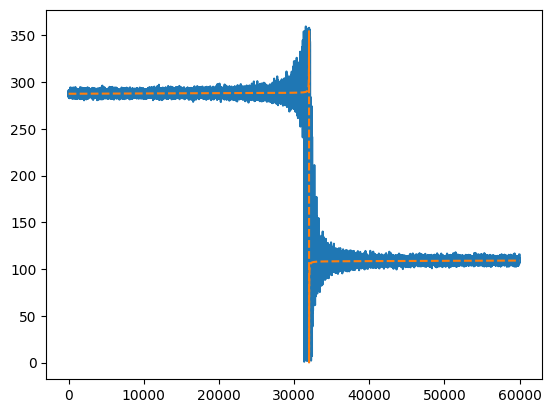

In [31]:
del_phi_1 = np.unwrap(np.angle(received_sig_noisy[0,:]/received_sig_noisy[1,:]))
del_phi_2 = np.unwrap(np.angle(received_sig_noisy[0,:]/received_sig_noisy[2,:]))

#a = (np.arctan(del_phi_2/del_phi_1))
az = np.arctan2(del_phi_1, del_phi_2)
el = np.arccos(del_phi_1*lam/(2*np.pi*d*np.sin(az))) 
az = np.unwrap(-az+np.pi/2)
az = np.where(az%(2*np.pi)<0, 2*np.pi-np.abs(az), az%(2*np.pi))

# plt.figure()
# plt.plot(np.rad2deg(a))
# az = np.arctan2(del_phi_2, del_phi_1)

plt.figure()
plt.plot(np.rad2deg(el))
# plt.plot(90-np.abs(90-np.degrees(el)))
plt.plot(el_gt, linestyle='--')

plt.figure()
plt.plot(np.rad2deg(az))
plt.plot(az_gt, linestyle='--')
plt.plot()